# Prototipo funcional · Anticipación de cupos por programa y año de estudio
Desarrollo de Soluciones Inteligentes (UBO) · Proyecto Integrador · EVAL-01 (13-11-2026), corregido para EVAL-02 (27-11-2026)

**Equipo:** Ivan Oliva y Bastian Gonzalez, Paralelo 2

**Problema.** Planificación académica necesita saber cuántos estudiantes de cada cohorte seguirán el próximo año en el mismo programa, para dimensionar secciones, docentes y salas de los años superiores.
**Qué hace el prototipo.** Recibe cohortes (caso a caso, o una tabla), valida los datos, aplica un modelo Random Forest ya entrenado (sin reajustarlo) y entrega la continuidad estimada, los estudiantes esperados y los cupos esperados por programa y año de estudio, con avisos cuando la estimación es menos fiable.
**Alcance.** Solo universidades, y cupos por programa y año de estudio, no por asignatura (la base SIES no trae asignaturas). En CFT e IP muchos códigos de programa desaparecen de un año a otro y la base lo registra como «no continúa»; la aplicación rechaza esas cohortes.

Para ejecutarlo: dejar `modelo_continuidad.joblib`, `contrato_modelo.json`, `cupos_app.py`, `casos_prueba.py`, `datos_ejemplo/` y `evidencia/` junto a este notebook (en Colab, subir el zip del prototipo y descomprimir en la primera celda). Dependencias en `requirements.txt`.

In [1]:
import os, sys, glob, zipfile, json, platform
z = glob.glob('/content/*.zip') + glob.glob('*.zip')
if not z and not glob.glob('**/cupos_app.py', recursive=True):
    from google.colab import files
    files.upload(); z = glob.glob('*.zip')
if z:
    zipfile.ZipFile(z[0]).extractall('.')   # siempre se vuelve a extraer: evita quedarse con una versión antigua
os.chdir(os.path.dirname(os.path.abspath(glob.glob('**/cupos_app.py', recursive=True)[0])))
sys.path.insert(0, os.getcwd())
sys.modules.pop('cupos_app', None); sys.modules.pop('casos_prueba', None)
import numpy as np, pandas as pd, sklearn, matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import cupos_app as app
assert hasattr(app, '_parsear'), 'cupos_app.py es una versión antigua: borre la carpeta PI06_Prototipo_Cupos, reinicie la sesión y vuelva a ejecutar'
from casos_prueba import ejecutar_casos
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 120)
M = app.Modelo()   # verifica la huella del modelo contra el contrato antes de cargarlo
print('python', platform.python_version(), '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__)
print('modelo creado con scikit-learn', M.contrato['versiones']['sklearn'], '| entrenado con', M.contrato['filas_entrenamiento'], 'cohortes (t = 2019-2024)')

python 3.13.18 | pandas 2.2.3 | scikit-learn 1.8.0
modelo creado con scikit-learn 1.8.0 | entrenado con 2312 cohortes (t = 2019-2024)


## Demo en vivo: ingresar datos y predecir
Escriba o cambie los datos de una cohorte y pulse **Predecir**. Las listas desplegables traen las categorías válidas. Los campos opcionales pueden quedar vacíos. Para ver el rechazo, cargue un caso de prueba o escriba un valor inválido (por ejemplo arancel 55 o n_t 4).

In [2]:
import ipywidgets as w
from IPython.display import display, HTML, clear_output
base = json.load(open('datos_ejemplo/caso_valido.json', encoding='utf-8'))
PRESETS = {'Cohorte válida (real, ingreso 2023)': {}, 'Arancel en UF': dict(arancel_anual_clp=55.0), 'Cohorte de 4 estudiantes': dict(n_t=4),
           'Proporción mayor que 1': dict(ret_prev=1.4), 'CFT (fuera de alcance)': dict(tipo_inst_1='Centros de Formación Técnica'),
           'Sin historial ni edad (aviso)': dict(n_prev=None, ret_prev=None, edad_media=None), 'Último año de la carrera': dict(anio_ingreso=2022)}
est = {'description_width': '190px'}; lay = w.Layout(width='470px')
CAMPOS_W = {}
for n, tipo, lo, hi, obl, un in app.NUMERICOS:
    CAMPOS_W[n] = w.Text(description=f"{n} ({un}){'' if obl else ' *'}", style=est, layout=lay)
for c in app.CATEGORICOS:
    CAMPOS_W[c] = w.Dropdown(options=M.categorias[c], description=c, style=est, layout=lay)
def cargar(valores):
    for k, wd in CAMPOS_W.items():
        v = valores.get(k)
        wd.value = ('' if v is None else str(v)) if isinstance(wd, w.Text) else v
cargar(base)
sel = w.Dropdown(options=list(PRESETS), description='Cargar caso:', style=est, layout=lay)
sel.observe(lambda ch: cargar({**base, **PRESETS[ch['new']]}), names='value')
btn = w.Button(description='Predecir', button_style='primary'); salida = w.Output()
def predecir_ui(_):
    with salida:
        clear_output()
        entrada = {k: (app._parsear(wd.value) if isinstance(wd, w.Text) else wd.value) for k, wd in CAMPOS_W.items()}
        r = app.predecir(M, entrada); app._mostrar(r)
        if r['estado'] == 'OK':
            display(HTML(f"<h3>De {entrada['n_t']} estudiantes, se estima que {r['prediccion']*100:.0f}% (unos {r['estudiantes_esperados']:.1f}) seguirá en el mismo programa el año siguiente.</h3>"
                         f"<p>Error típico de referencia: ±{r['error_tipico_pp']} puntos porcentuales. Es una estimación, no una certeza.</p>"))
btn.on_click(predecir_ui)
display(w.VBox([sel] + list(CAMPOS_W.values()) + [w.HTML('<small>* opcional: puede quedar vacío</small>'), btn, salida]))

## 1. Arquitectura

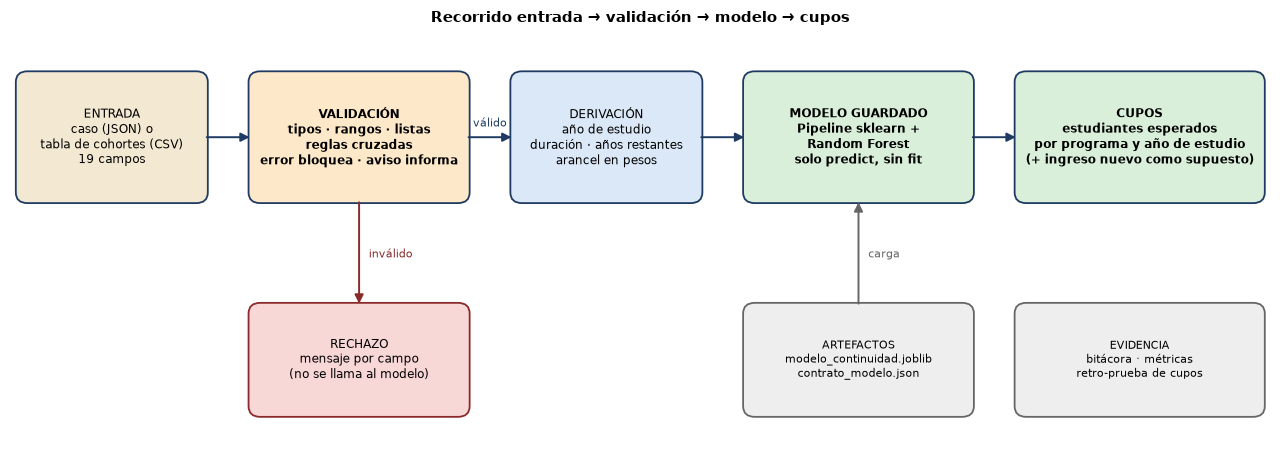

In [3]:
fig, ax = plt.subplots(figsize=(13, 4.6)); ax.set_xlim(0, 13); ax.set_ylim(0, 4.6); ax.axis('off')
def caja(x, y, w, h, t, c='#dbe8f7', ec='#1f3b63', fs=8.8, b=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.04,rounding_size=0.12', fc=c, ec=ec, lw=1.3))
    ax.text(x + w / 2, y + h / 2, t, ha='center', va='center', fontsize=fs, fontweight='bold' if b else 'normal')
def fl(x1, y1, x2, y2, t='', c='#1f3b63'):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle='-|>', mutation_scale=13, lw=1.4, color=c))
    if t: ax.text((x1 + x2) / 2, (y1 + y2) / 2 + .12, t, ha='center', fontsize=7.8, color=c)
caja(.1, 2.7, 1.9, 1.4, 'ENTRADA\ncaso (JSON) o\ntabla de cohortes (CSV)\n19 campos', c='#f3e9d2')
caja(2.5, 2.7, 2.2, 1.4, 'VALIDACIÓN\ntipos · rangos · listas\nreglas cruzadas\nerror bloquea · aviso informa', c='#fde9c9', b=True)
caja(5.2, 2.7, 1.9, 1.4, 'DERIVACIÓN\naño de estudio\nduración · años restantes\narancel en pesos')
caja(7.6, 2.7, 2.3, 1.4, 'MODELO GUARDADO\nPipeline sklearn +\nRandom Forest\nsolo predict, sin fit', c='#d9efd9', b=True)
caja(10.4, 2.7, 2.5, 1.4, 'CUPOS\nestudiantes esperados\npor programa y año de estudio\n(+ ingreso nuevo como supuesto)', c='#d9efd9', b=True)
caja(2.5, .3, 2.2, 1.2, 'RECHAZO\nmensaje por campo\n(no se llama al modelo)', c='#f8d7d7', ec='#8a2a2a')
caja(7.6, .3, 2.3, 1.2, 'ARTEFACTOS\nmodelo_continuidad.joblib\ncontrato_modelo.json', c='#eeeeee', ec='#666666', fs=8.2)
caja(10.4, .3, 2.5, 1.2, 'EVIDENCIA\nbitácora · métricas\nretro-prueba de cupos', c='#eeeeee', ec='#666666', fs=8.2)
fl(2.0, 3.4, 2.5, 3.4); fl(4.7, 3.4, 5.2, 3.4, 'válido'); fl(7.1, 3.4, 7.6, 3.4); fl(9.9, 3.4, 10.4, 3.4)
fl(3.6, 2.7, 3.6, 1.5, c='#8a2a2a'); ax.text(3.7, 2.05, 'inválido', fontsize=7.8, color='#8a2a2a')
fl(8.75, 1.5, 8.75, 2.7, c='#666666'); ax.text(8.85, 2.05, 'carga', fontsize=7.8, color='#666666')
ax.set_title('Recorrido entrada → validación → modelo → cupos', fontweight='bold', fontsize=11)
fig.tight_layout(); os.makedirs('evidencia', exist_ok=True); fig.savefig('evidencia/arquitectura.png', dpi=160); plt.show()

## 2. Contrato de entrada

In [4]:
tabla = pd.DataFrame([dict(campo=n, tipo=t, minimo=lo, maximo=hi, obligatorio=o, unidad=u) for n, t, lo, hi, o, u in app.NUMERICOS] +
                     [dict(campo=c, tipo='texto', minimo=None, maximo=None, obligatorio=True, unidad='lista cerrada de entrenamiento') for c in app.CATEGORICOS])
display(tabla)
print('Reglas cruzadas: anio_ingreso <= anio_t; n_t <= prog_total_t; n_prev y ret_prev van juntos; cohorte nueva sin historial; la cohorte debe tener un año nominal por delante.')

,campo,tipo,minimo,maximo,obligatorio,unidad
0,anio_t,entero,2019.0,2.040000e+03,True,año
1,anio_ingreso,entero,1990.0,NaN,True,año
2,n_t,entero,5.0,1.000000e+06,True,estudiantes
3,prog_total_t,entero,1.0,1.000000e+06,True,estudiantes
4,n_prev,entero,1.0,1.000000e+06,False,estudiantes
5,ret_prev,real,0.0,1.000000e+00,False,proporción
6,prop_mujer,real,0.0,1.000000e+00,True,proporción
7,edad_media,real,14.0,9.000000e+01,False,años
8,dur_semestres,entero,1.0,2.000000e+01,True,semestres
9,arancel_anual_clp,real,10000.0,1.000000e+10,False,pesos chilenos por año


Reglas cruzadas: anio_ingreso <= anio_t; n_t <= prog_total_t; n_prev y ret_prev van juntos; cohorte nueva sin historial; la cohorte debe tener un año nominal por delante.


## 3. Demostración con un caso: entrada → proceso → resultado

In [5]:
caso = json.load(open('datos_ejemplo/caso_valido.json', encoding='utf-8'))   # cohorte universitaria real, ingreso 2023, observada en 2025
print(json.dumps({k: caso[k] for k in list(caso)[:10]}, ensure_ascii=False)); print('... + 9 campos de texto')
r = app.predecir(M, caso); app._mostrar(r)

{"anio_t": 2025, "anio_ingreso": 2023, "n_t": 22, "n_prev": 23, "ret_prev": 0.9565, "prog_total_t": 45, "prop_mujer": 0.3182, "edad_media": 22.6818, "dur_semestres": 8, "arancel_anual_clp": 4347000.0}
... + 9 campos de texto
ESTADO: OK
  continuidad estimada: 0.860 | estudiantes esperados: 18.9 | año de estudio siguiente: 4 | error típico: ±7.2 pp


In [6]:
# Entradas inválidas: se rechazan antes del modelo
antes = M.llamadas
for nombre, cambio in [('arancel en UF', dict(arancel_anual_clp=55.0)), ('región inexistente', dict(region_sede='Narnia')),
                       ('proporción mayor que 1', dict(ret_prev=1.4)), ('cohorte de 4 estudiantes', dict(n_t=4))]:
    print('>>', nombre); app._mostrar(app.predecir(M, {**caso, **cambio}))
print('\nllamadas al modelo en los 4 casos inválidos:', M.llamadas - antes)

>> arancel en UF
ESTADO: RECHAZADA
  ERROR       : arancel_anual_clp=55: parece estar en UF; debe informarse en pesos chilenos por año (mínimo 10,000)
>> región inexistente
ESTADO: RECHAZADA
  ERROR       : region_sede: categoría no reconocida ('Narnia'); opciones: Antofagasta, Arica y Parinacota, Atacama, Aysén, Biobío, Coquimbo, La Araucanía, Lib. Gral. B. O'Higgins, Los Lagos, Los Ríos, Magallanes, Maule, Metropolitana, Tarapacá, Valparaíso, Ñuble
>> proporción mayor que 1
ESTADO: RECHAZADA
  ERROR       : ret_prev=1.4: mayor que el máximo permitido (1.0 proporción)
>> cohorte de 4 estudiantes
ESTADO: RECHAZADA
  ERROR       : n_t=4: una cohorte de menos de 5 estudiantes no es estimable (el modelo se entrenó con 5 o más)

llamadas al modelo en los 4 casos inválidos: 0


## 4. Modo lote: de cohortes a cupos por programa y año de estudio

In [7]:
cohortes = app._csv_a_df('datos_ejemplo/cohortes_2025.csv')       # 328 cohortes universitarias observadas en 2025 (datos agregados, sin personas)
detalle, cupos = app.proyectar_lote(M, cohortes)
print(detalle.estado.value_counts().to_dict(), '| cohortes con algún aviso:', int((detalle.mensajes != '').sum()))
p = cupos.programa.iloc[20]
print('\nEjemplo, programa', p, '(cupos esperados en 2026):'); display(cupos[cupos.programa == p])
print('Filas excluidas en total:', int((detalle.estado != 'OK').sum()), '| programas sin dato de ingreso para el año 1:', int(cupos.cupos_esperados.isna().sum()))
display(cupos.groupby('anio_estudio_t1').cupos_esperados.agg(['count', 'sum']).round(0).rename(columns={'count': 'programas', 'sum': 'cupos_esperados'}))

{'OK': 328} | cohortes con algún aviso: 8

Ejemplo, programa I13S11C34J1V1 (cupos esperados en 2026):


,programa,anio_t1,anio_estudio_t1,cupos_esperados,origen,filas_excluidas
17,I13S11C34J1V1,2026,1,42.0,supuesto: igual al ingreso de t,0
18,I13S11C34J1V1,2026,2,34.6,continuidad (modelo),0
19,I13S11C34J1V1,2026,3,31.7,continuidad (modelo),0
20,I13S11C34J1V1,2026,4,31.8,continuidad (modelo),0
21,I13S11C34J1V1,2026,5,25.2,continuidad (modelo),0


Filas excluidas en total: 0 | programas sin dato de ingreso para el año 1: 10


,programas,cupos_esperados
anio_estudio_t1,,
1,99,6177.0
2,99,4918.0
3,89,3899.0
4,69,3004.0
5,60,2177.0
6,11,428.0


El año 1 de 2026 no lo predice el modelo: se toma el ingreso observado en 2025 como **supuesto** (o un ingreso proyectado entregado por el usuario), solo si esa fila fue aceptada. Sin un dato válido queda vacío y la columna `origen` dice por qué.

Una cohorte se identifica por programa + `anio_t` + `anio_ingreso`. Si se repite, todas sus filas quedan como `DUPLICADA` y ninguna suma; las filas rechazadas tampoco suman. Abajo se muestra con un lote armado a propósito.


In [8]:
# lote de prueba: una cohorte repetida y una fila de ingreso con 4 estudiantes
g = cohortes[cohortes.programa == p]
malo = pd.concat([g, g.iloc[[1]]], ignore_index=True)
ingreso = malo.anio_ingreso == malo.anio_t
malo.loc[ingreso, 'n_t'] = 4
d_malo, c_malo = app.proyectar_lote(M, malo)
display(d_malo[['fila', 'anio_ingreso', 'n_t', 'estado', 'mensajes']])
display(c_malo)

,fila,anio_ingreso,n_t,estado,mensajes
0,0,2022,29,OK,
1,1,2023,35,DUPLICADA,"cohorte repetida (programa I13S11C34J1V1, anio_t 2025, anio_ingreso 2023) en las filas 1, 4: no se suma ninguna; dej..."
2,2,2024,35,OK,
3,3,2025,4,RECHAZADA,n_t=4: una cohorte de menos de 5 estudiantes no es estimable (el modelo se entrenó con 5 o más)
4,4,2023,35,DUPLICADA,"cohorte repetida (programa I13S11C34J1V1, anio_t 2025, anio_ingreso 2023) en las filas 1, 4: no se suma ninguna; dej..."


,programa,anio_t1,anio_estudio_t1,cupos_esperados,origen,filas_excluidas
0,I13S11C34J1V1,2026,1,NaN,sin dato: la fila de ingreso de t fue rechazada; entregar el ingreso proyectado,3
1,I13S11C34J1V1,2026,3,31.7,continuidad (modelo),3
2,I13S11C34J1V1,2026,5,25.2,continuidad (modelo),3


## 5. Pruebas: bitácora de 25 casos (ejecución en vivo)
20 casos de una cohorte y 5 del modo lote (duplicados, ingreso rechazado, ingreso dado, totales y alcance).

In [9]:
BIT, _ = ejecutar_casos(app.Modelo())
display(BIT[['caso', 'tipo', 'proposito', 'estado_observado', 'llamadas_modelo', 'resultado']])
print(f"{(BIT.resultado == 'Cumple').sum()} de {len(BIT)} casos cumplen | llamadas al modelo en casos de error:", int(BIT[BIT.estado_observado == 'RECHAZADA'].llamadas_modelo.sum()))

,caso,tipo,proposito,estado_observado,llamadas_modelo,resultado
0,CP-01,Normal,flujo completo con una cohorte real,OK,1,Cumple
1,CP-02,Inválido,arancel negativo,RECHAZADA,0,Cumple
2,CP-03,Incompleto,falta un campo obligatorio (prop_mujer),RECHAZADA,0,Cumple
3,CP-04,Inválido,texto en campo numérico,RECHAZADA,0,Cumple
4,CP-05,Integración,misma predicción que el pipeline de referencia,OK,1,Cumple
5,CP-06,Fuera de rango,arancel tres veces el máximo de entrenamiento,OK,1,Cumple
6,CP-07,Límite,n_t = 0,RECHAZADA,0,Cumple
7,CP-08,Límite,"n_t = 4, justo bajo el mínimo del contrato",RECHAZADA,0,Cumple
8,CP-09,No finito,NaN en ret_prev,RECHAZADA,0,Cumple
9,CP-10,No finito,infinito en el arancel,RECHAZADA,0,Cumple


25 de 25 casos cumplen | llamadas al modelo en casos de error: 0


### Pruebas ampliadas (resultados guardados en `evidencia/`)
Además de la bitácora hay dos suites que se ejecutan aparte (`pruebas_escenarios.py` y `pruebas_adversarias.py`, cerca de un minuto cada una). Aquí se leen sus resultados.

In [10]:
ESC = json.load(open('evidencia/resumen_escenarios.json', encoding='utf-8'))
ADV = pd.read_csv('evidencia/pruebas_adversarias.csv')
print(f"Escenarios contra el verificador independiente: {ESC['cumplen']:,} de {ESC['total']:,} cumplen | excepciones: {ESC['excepciones']} | rechazos que llegaron al modelo: {ESC['rechazados_que_llegaron_al_modelo']}")
print(f"Casos adversarios: {(ADV.resultado == 'Cumple').sum()} de {len(ADV)} cumplen")
display(ADV.groupby('grupo').resultado.value_counts().unstack(fill_value=0))

Escenarios contra el verificador independiente: 41,279 de 41,279 cumplen | excepciones: 0 | rechazos que llegaron al modelo: 0
Casos adversarios: 122 de 122 cumplen


resultado,Cumple
grupo,
CSV,14
concurrencia,3
consistencia,5
integridad,5
lote,17
línea de comandos,8
números escritos a mano,14
números extremos,15
servidor web,15


## 6. Validación con datos reales (resultados de `ejecutar_validacion.py`)
Se calcularon al ejecutar el script sobre la muestra SIES (partición temporal: entrenamiento con cohortes observadas en 2019–2024, prueba en 2025 con el objetivo construido con la matrícula 2026). Además se validó con cortes en 2022, 2023 y 2024, cada uno entrenado solo con los años anteriores. Aquí solo se leen los archivos de `evidencia/`.

In [11]:
R = json.load(open('evidencia/resumen_evidencia.json', encoding='utf-8'))
print('Cohortes de entrenamiento:', R['datos']['cohortes_entrenamiento'], '| prueba:', R['datos']['cohortes_prueba'], '| SHA-256 del zip de datos:', R['datos']['sha256_zip'][:16], '...')
print('Modelo guardado = reentrenado:', R['modelo_guardado_igual_reentrenado'], '| integración app vs pipeline:', R['integracion'], '| pipeline sin cambios tras predecir:', R['sin_reajuste']['igual'])
print('\nContinuidad (proporción) en la prueba 2025'); display(pd.read_csv('evidencia/metricas_continuidad.csv', index_col=0))
print('Cupos: estudiantes continuantes esperados vs observados (2025 → 2026)'); display(pd.read_csv('evidencia/cupos_backtest_todas.csv', index_col=0))
print('Elección del modelo: validación 2022-2024 (2025 no se usó para elegir)'); display(pd.read_csv('evidencia/comparacion_modelos.csv', index_col=0))
print('Varios cortes temporales (cada uno entrena con los años anteriores)'); display(pd.read_csv('evidencia/validacion_temporal.csv'))

Cohortes de entrenamiento: 2312 | prueba: 331 | SHA-256 del zip de datos: 5b69ea7154e08990 ...
Modelo guardado = reentrenado: True | integración app vs pipeline: {'cohortes_en_contrato': 328, 'coinciden': 328, 'fuera_por_arancel_en_uf': 3} | pipeline sin cambios tras predecir: True

Continuidad (proporción) en la prueba 2025


,MAE,MAE_ponderado_n,RMSE,R2,sesgo
Random Forest (modelo),0.0723,0.0641,0.1026,0.2360,-0.0250
Base: media de entrenamiento,0.0981,0.0964,0.1261,-0.1551,-0.0462
Base: retención del año previo,0.0886,0.0747,0.1293,-0.2134,-0.0205


Cupos: estudiantes continuantes esperados vs observados (2025 → 2026)


,MAE_est_por_cohorte,WAPE_cohorte,MAE_est_por_programa,WAPE_programa,sesgo_total_pct
Modelo,3.2903,0.0736,7.1281,0.0530,-2.3092
Base: todos continúan,6.6707,0.1493,20.0727,0.1493,14.9300
Base: media de entrenamiento,4.9498,0.1108,12.2675,0.0912,-6.1201
Base: retención del año previo,3.8376,0.0859,7.1192,0.0530,-1.9074


Elección del modelo: validación 2022-2024 (2025 no se usó para elegir)


,2022,2023,2024,MAE_medio
modelo,,,,
"Random Forest (300 árboles, prof. 5)",0.1081,0.0969,0.0876,0.0975
Ridge (alpha = 1),0.1253,0.1041,0.0917,0.1070
Constante (mediana),0.1273,0.1151,0.0949,0.1125
Persistencia (retención previa),0.1320,0.1298,0.1084,0.1234


Varios cortes temporales (cada uno entrena con los años anteriores)


,anio_prueba,anios_entrenamiento,filas_entrenamiento,filas_prueba,MAE,MAE_base_media,MAE_base_ret_prev,sesgo
0,2022,2019-2021,1266,365,0.1081,0.1291,0.1237,0.0324
1,2023,2019-2022,1631,347,0.0969,0.1243,0.1216,0.0085
2,2024,2019-2023,1978,334,0.0876,0.1113,0.1040,-0.0157
3,2025,2019-2024,2312,331,0.0723,0.0981,0.0886,-0.0250


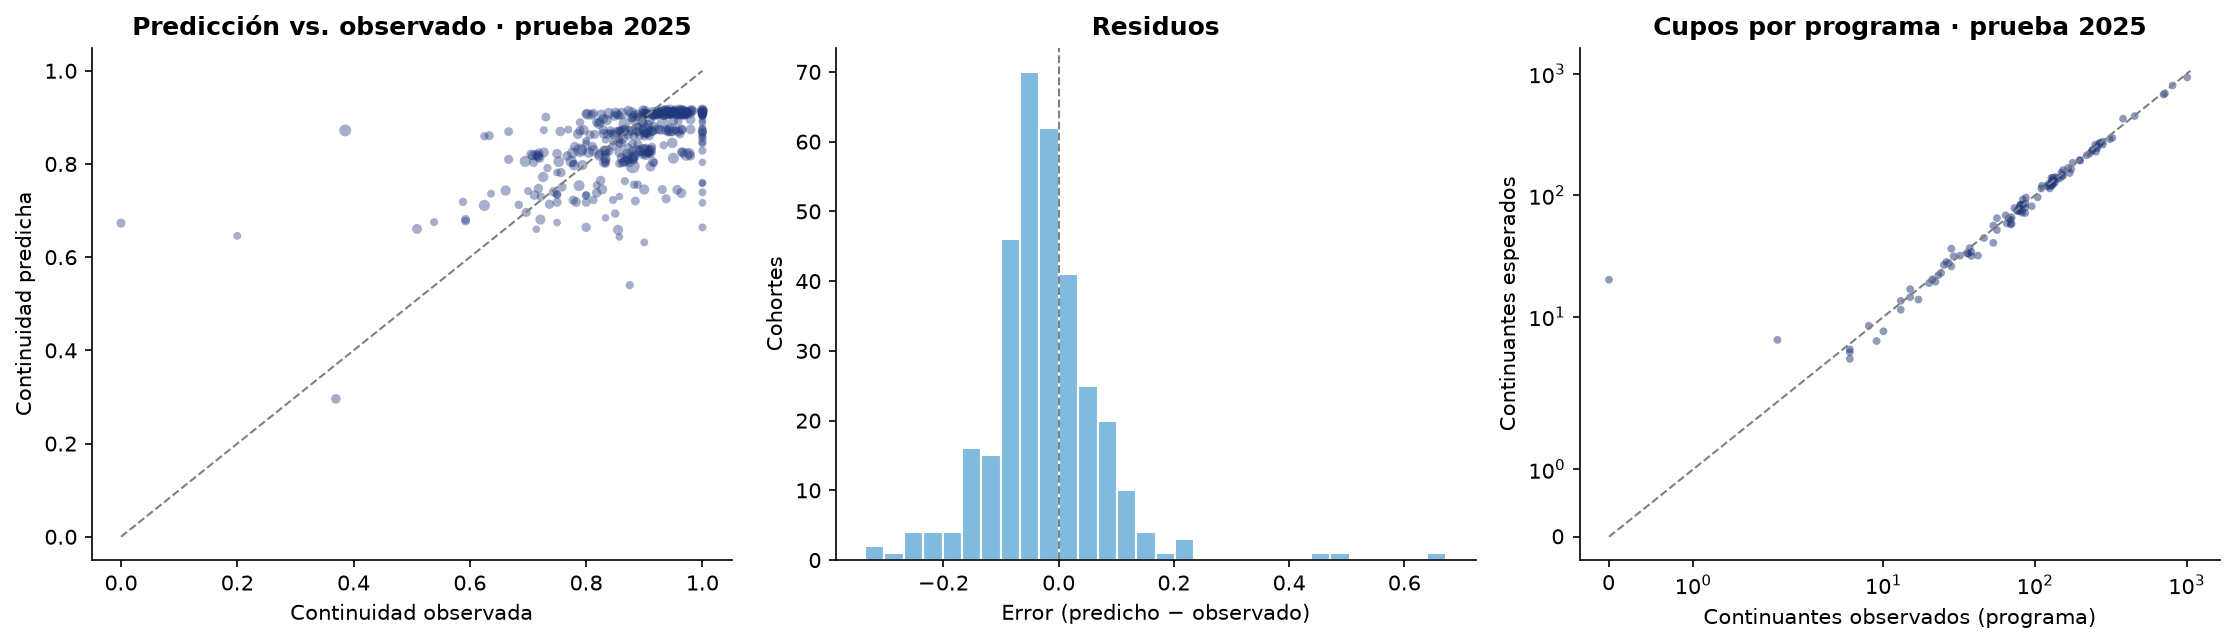

In [12]:
from IPython.display import Image, display as d2
d2(Image('evidencia/fig_desempeno.png'))

### Alcance y dónde falla

Cohortes cuyo código de programa ya no existe al año siguiente, por tipo de institución


,anio_t,tipo_inst_1,cohortes,pct_codigo_desaparece,continuidad_media
0,2023,Centros de Formación Técnica,87,5.7,0.6596
1,2023,Institutos Profesionales,356,3.1,0.6925
2,2023,Universidades,347,2.0,0.8166
3,2024,Centros de Formación Técnica,101,1.0,0.6774
4,2024,Institutos Profesionales,359,1.1,0.7122
5,2024,Universidades,334,0.6,0.8484
6,2025,Centros de Formación Técnica,103,26.2,0.5049
7,2025,Institutos Profesionales,340,2.1,0.7050
8,2025,Universidades,331,0.3,0.8631


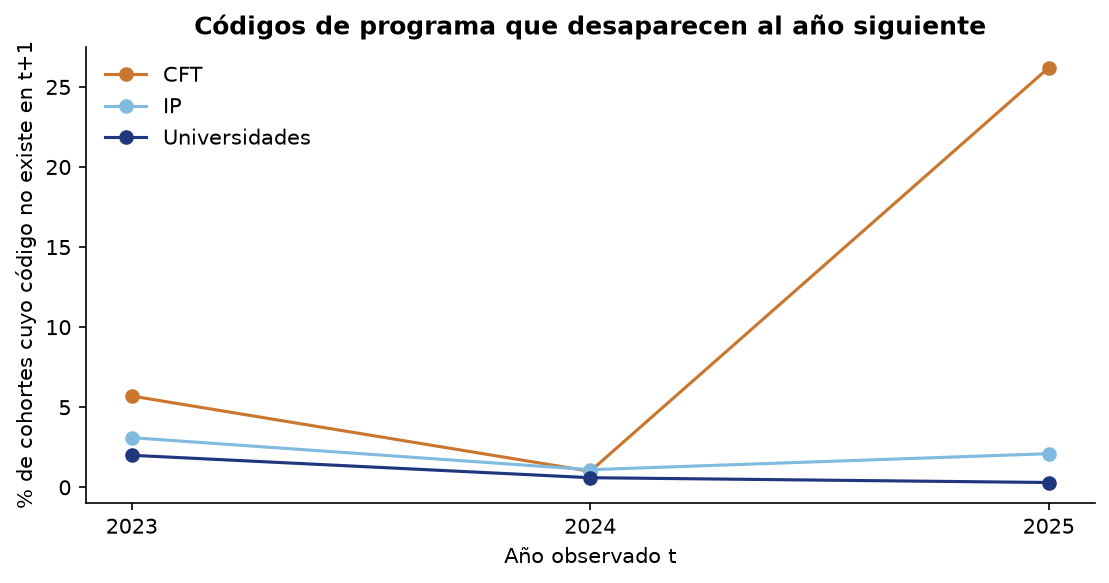

Error por tamaño de cohorte


,cohortes,observado_medio,prediccion_media,MAE,sesgo
tramo_n_t,,,,,
20–49,146,0.8585,0.8420,0.0668,-0.0164
50 o más,119,0.8752,0.8556,0.0589,-0.0195
10–19,48,0.8319,0.8000,0.1043,-0.0319
5–9,18,0.9034,0.7918,0.1199,-0.1117


Error por área


,cohortes,observado_medio,prediccion_media,MAE,sesgo
area_conocimiento,,,,,
Salud,90,0.8998,0.8706,0.0577,-0.0292
Tecnología,75,0.8254,0.8157,0.0816,-0.0097
Educación,44,0.9087,0.8489,0.0732,-0.0598
Ciencias Sociales,41,0.8387,0.8263,0.0907,-0.0123
Administración y Comercio,32,0.8363,0.7925,0.0846,-0.0438
Derecho,22,0.8488,0.8526,0.0559,0.0038
Ciencias Básicas,13,0.8150,0.8354,0.0502,0.0205
Arte y Arquitectura,10,0.8873,0.8480,0.0693,-0.0393
Agropecuaria,4,0.8777,0.7965,0.0960,-0.0813


In [13]:
print('Cohortes cuyo código de programa ya no existe al año siguiente, por tipo de institución'); display(pd.read_csv('evidencia/alcance_por_tipo.csv'))
d2(Image('evidencia/fig_alcance.png'))
print('Error por tamaño de cohorte'); display(pd.read_csv('evidencia/error_por_tamano_cohorte.csv', index_col=0))
print('Error por área'); display(pd.read_csv('evidencia/error_por_area.csv', index_col=0))

## 7. Lectura de resultados, límites y riesgos
- **Elección del modelo:** en la validación 2022–2024 (sin tocar 2025), Random Forest obtuvo 0,098 de MAE medio, contra 0,107 de Ridge, 0,113 de la constante y 0,123 de la persistencia. Con el criterio fijado antes de comparar (menor MAE, salvo diferencias menores a 0,002) se cambió Ridge por Random Forest.
- **El modelo mejora a las líneas base** en la prueba 2025: MAE 0,072 contra 0,089 de repetir la retención del año previo y 0,098 de la media, y les gana en los cuatro cortes temporales (2022 a 2025).
- **R² modesto (0,24):** en universidades la continuidad es alta y varía poco. Sirve para anticipar, no para fijar cupos exactos.
- **Cupos:** por cohorte, el modelo erra 3,29 estudiantes contra 3,84 de la retención previa; sumado por programa quedan empatados (7,13 contra 7,12).
- **Alcance:** solo universidades. En CFT, el 26,2% de las cohortes de 2025 tienen un código que desaparece en 2026; eso no es continuidad real.
- **Cohortes pequeñas** (5–9 estudiantes) tienen el mayor error (MAE 0,120) y el modelo las subestima.
- **Sensibilidad:** un Random Forest responde por tramos; mover la retención previa 5 puntos cambia la predicción en más de 2 puntos en una de cada cuatro cohortes.
- **No predice el ingreso nuevo** (año 1): es un supuesto explícito o un dato del usuario.
- **Datos:** muestra del 4% de los programas; datos públicos y anonimizados, agregados por cohorte. Ver `DATOS.md`.
- **Uso responsable:** la estimación apoya la planificación, no decide sobre personas. Usa proporción de mujeres y edad media como predictores de cohorte; no se evaluó equidad.

In [14]:
print('Regenerar el modelo (requiere T04_muestra_SIES_2017_2026.zip):  python construir_modelo.py T04_muestra_SIES_2017_2026.zip')
print('Regenerar la evidencia:                                         python ejecutar_validacion.py T04_muestra_SIES_2017_2026.zip')

Regenerar el modelo (requiere T04_muestra_SIES_2017_2026.zip):  python construir_modelo.py T04_muestra_SIES_2017_2026.zip
Regenerar la evidencia:                                         python ejecutar_validacion.py T04_muestra_SIES_2017_2026.zip
